# AESTRA II tutorial

This notebook walks through the steps of AESTRA II
([Liang et al., AJ, accepted; arXiv:2606.13574](https://arxiv.org/abs/2606.13574))
on a small demo data set: two NEID echelle orders (51 and 52, 5011–5094 Å) of
1,000 solar spectra, the telluric models of these two orders, and a stellar
activity model trained on these spectra. It runs the steps from the per-order
spectra to the stellar activity representation in about a minute (faster with a
GPU). The steps that need the NEID Level-2 files or many hours of training, and
the RV decomposition, which needs a longer RV time series than the demo, are
shown as commands, but not run.

**Demo data.** The demo data (116 MB) are attached to the AESTRA II release of this
repository. Download and unpack them in the repository root:

```
curl -L https://github.com/yanliang-astro/aestra/releases/download/paper-II/aestra2_demo.tar.gz | tar xz
```

or download `aestra2_demo.tar.gz` from the release page and unpack it there. This creates

```
demo/newprod_order{51,52}_full_{0,1}.pt          spectra of each order, 500 per batch file
demo/newprod_order{51,52}_full-template.pt       template of each order
demo/newprod_order{51,52}_full-param.pt          metadata of every observation
demo/skymodel/sky_order{51,52}_full.pt           telluric models (step 2)
demo/stellar_model/stellar_s20.pt                stellar activity model (step 6)
```

Run the notebook from the repository root. The scripts write their outputs into `demo/`.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image as PILImage

from data import SpectralData, load_batch
from models import load_sky_model
from util import interpolate_to_input_grid_raw

DEMO = "demo"
ORDERS = (51, 52)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#898781")
    ax.tick_params(colors="#52514e", labelsize=9)

device: cuda


## 1. Per-order spectra — `prepare_orders.py`

`prepare_orders.py` turns NEID Level-2 files into per-order spectra (paper
Sec. 3.1–3.2): it keeps the free-spectral-range pixels of each order, divides the
flux by the blaze and its median, computes inverse-variance weights, masks
single-pixel spikes, rejects outlying spectra and corrects a bulk RV offset of
each order before and after the 2022 shutdown. It needs the L2 files and the NEID
FSR mask, so it is not run here:

```
./prepare_orders.py --l2 /path/to/L2 --fsr_mask /path/to/neidMaster_FSR_Mask20210218_v002.fits \
    --dir data/ --n_sample 30000
```

Its output for one order is a set of batch files, a template and a param file:

In [2]:
batch = load_batch(f"{DEMO}/newprod_order51_full_0.pt")
wave, flux, weight, ssbrv, spectrum_id = batch[0]
print(f"batch file: {len(batch)} spectra, each (wavelengths, flux, weight, SSBRV, id) with {len(wave)} pixels")
print(f"first spectrum: SSBRV = {ssbrv.item():.1f} m/s, id = JD - 2459000 = {spectrum_id.item():.4f}")

template = load_batch(f"{DEMO}/newprod_order51_full-template.pt")
print(f"template: wavelengths, flux and weight on the order's model grid, shape {tuple(template[0].shape)}")

params = torch.load(f"{DEMO}/newprod_order51_full-param.pt", weights_only=False)
name = params["info"]["sample_names"][0]
print(f"metadata of {name}:")
for key, value in params[name].items():
    print(f"   {key:10s} {value}")

batch file: 500 spectra, each (wavelengths, flux, weight, SSBRV, id) with 4000 pixels
first spectrum: SSBRV = 764.8 m/s, id = JD - 2459000 = 518.2325
template: wavelengths, flux and weight on the order's model grid, shape (1, 4006)
metadata of neidL2_20211030T173445.fits:
   OBSJD      2459518.232472465
   DATE-OBS   2021-10-30T17:34:45.621
   AIRMASS    1.4301
   E_VER      v1.4.2
   ZENITH     51.2796503936345
   WVAPOR     9.153987708275299
   SSBRV      764.7609241615927
   CCFRV      -618.9288757004418
   CCFRVMOD   -644.154197894929
   DVRMSMOD   0.23426010638341402
   timestamp  518.2324829101562


The spectra are on their own (Earth-frame) wavelength grid. Near a telluric line,
the line stays in place and deepens with the water vapor, while the stellar lines
move with the barycentric velocity:

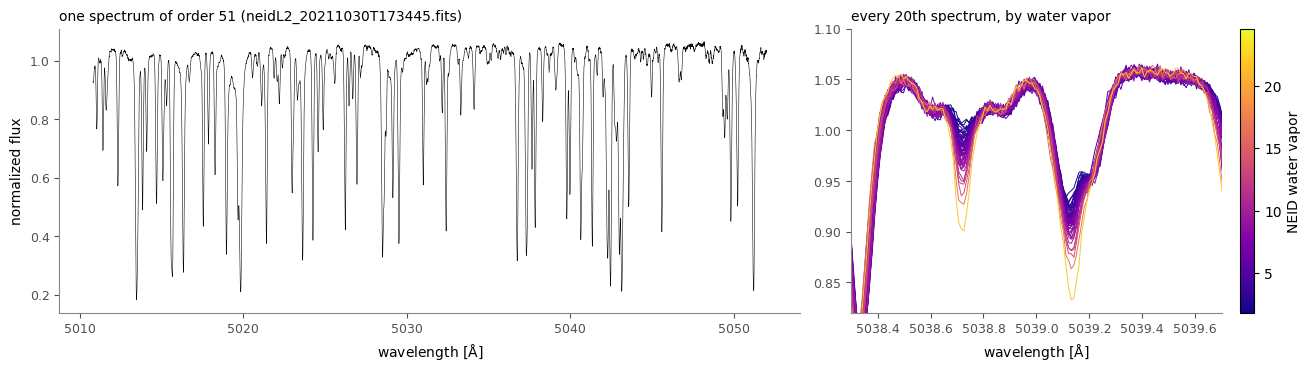

In [3]:
spectra = [s for f in SpectralData.list_batches(DEMO, "newprod_order51_full") for s in load_batch(f)]
name_of = {np.float32(m["timestamp"]).item(): n for n, m in params.items() if n != "info"}
wvap = np.array([params[name_of[s[4].item()]]["WVAPOR"] for s in spectra])
cmap, norm = plt.get_cmap("plasma"), plt.Normalize(*np.quantile(wvap, [0.01, 0.99]))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), width_ratios=(2, 1), constrained_layout=True)
w, f, wt = spectra[0][:3]
axs[0].plot(w, np.where(wt > 1, f, np.nan), color="#0b0b0b", lw=0.4)
axs[0].set_title(f"one spectrum of order 51 ({name_of[spectra[0][4].item()]})", loc="left", fontsize=10)
axs[0].set_ylabel("normalized flux")
for i in np.argsort(wvap)[::20]:
    w, f, wt = spectra[i][:3]
    axs[1].plot(w, np.where(wt > 1, f, np.nan), color=cmap(norm(wvap[i])), lw=0.7)
axs[1].set_xlim(5038.3, 5039.7)
axs[1].set_ylim(0.82, 1.1)
axs[1].set_title("every 20th spectrum, by water vapor", loc="left", fontsize=10)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axs[1], label="NEID water vapor")
for ax in axs:
    ax.set_xlabel(r"wavelength [$\mathrm{\AA}$]")
    style(ax)

## 2. Telluric model — `models.TelluricModel`, `tellurics_training.py`

Each order is modeled separately (Sec. 3.3, Eq. 1). An encoder maps every
spectrum to a few latents, and three decoders turn them into telluric lines
(convolved with a learned line-spread function), a smooth continuum, and stellar
line-shape variability:

  spectrum = [(1 − telluric lines)(1 + continuum)] shifted to the stellar frame × (template + stellar variability) + offset

The model of one order is trained in two stages (about an hour on a GPU), which
is not done here:

```
./tellurics_training.py --order 51 --dir data/ --batch_size 1000 --batch_number 1 --rate 2e-2 \
    --iteration 1000 --consistency --shuffle -v newprod_order skymodel/sky_order51_full.pt
./tellurics_training.py --order 51 --dir data/ --batch_size 3000 --batch_number 1 --rate 1e-3 \
    --iteration 3000 --shuffle --clobber -v newprod_order skymodel/sky_order51_full.pt
```

Here we load the trained model of order 51 and decompose one batch of spectra.
The spectra are first resampled onto the model's stellar-frame grid
(`util.interpolate_to_input_grid_raw`, with the learned pre-fire wavelength
correction):

In [4]:
order = 51
wave_obs, template = [t.to(device) for t in load_batch(f"{DEMO}/newprod_order{order}_full-template.pt")[:2]]
instrument = SpectralData(wave_obs)
sky = load_sky_model(f"{DEMO}/skymodel/sky_order{order}_full.pt", instrument, device)
batch = [torch.stack(x).to(device) for x in zip(*load_batch(f"{DEMO}/newprod_order{order}_full_0.pt"))]

with torch.no_grad():
    polyb = sky.evaluate_wavelength_polynomial(batch[0], batch[4])
    spectrum, w, ssbrv, ids = interpolate_to_input_grid_raw(batch, instrument, template, polyb=polyb)
    x = spectrum - template
    x[w < 1] = 0
    s = sky.encode(x)                                   # latents of every spectrum
    z = ssbrv / instrument.c
    lines, continuum, y_star, model = sky._forward(s, z, instrument.wave_obs)
    telluric = sky.transform(1 - lines, z, instrument.wave_obs)       # in the stellar frame
    smooth = sky.transform(1 + continuum, z, instrument.wave_obs)
print(f"{len(s)} spectra -> {s.shape[1]} latents each; model spectra {tuple(model.shape)}")

500 spectra -> 10 latents each; model spectra (500, 4006)


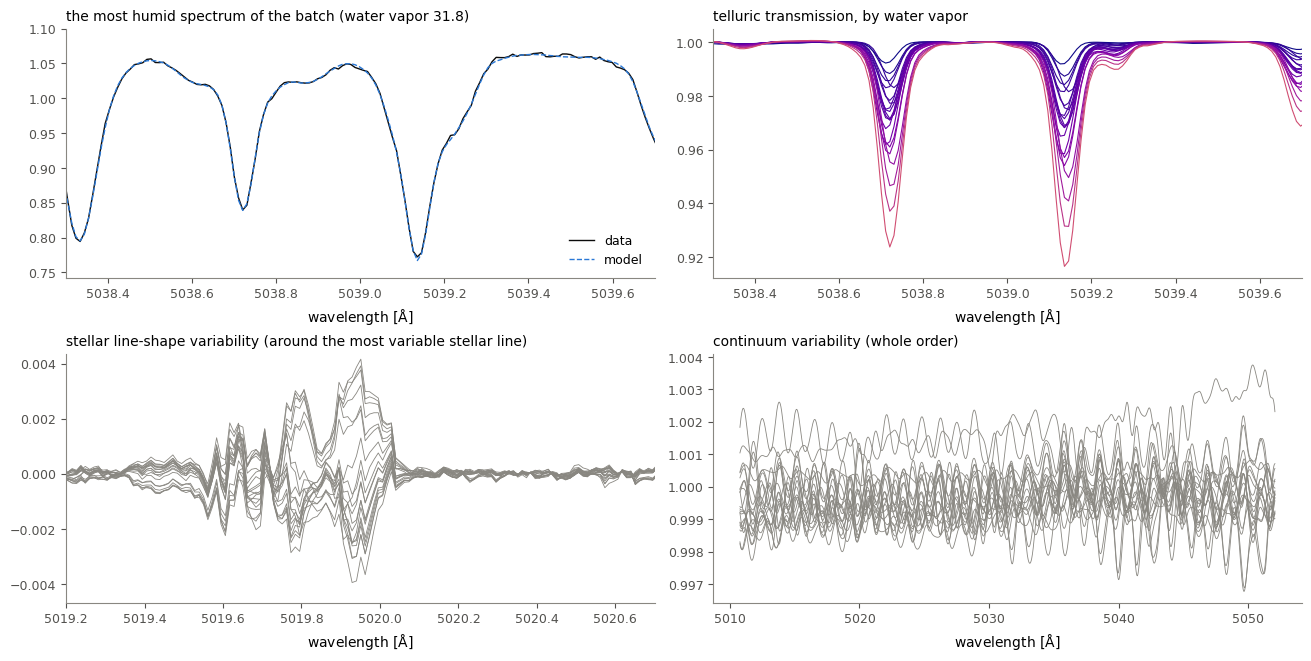

In [5]:
grid = wave_obs[0].cpu().numpy()
wv = np.array([params[name_of[i]]["WVAPOR"] for i in ids[:, 0].tolist()])
wet = int(np.argmax(wv))
good = (w[wet] > 1).cpu().numpy()
to_np = lambda t: t.cpu().numpy()

fig, axs = plt.subplots(2, 2, figsize=(13, 6.5), constrained_layout=True)
ax = axs[0, 0]
ax.plot(grid, np.where(good, to_np(spectrum[wet]), np.nan), color="#0b0b0b", lw=1, label="data")
ax.plot(grid, to_np(model[wet]), color="#2a78d6", lw=1, ls="--", label="model")
ax.set_title(f"the most humid spectrum of the batch (water vapor {wv[wet]:.1f})", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="lower right")
window = (grid > 5038.3) & (grid < 5039.7)
ax.set_ylim(np.nanmin(np.where(good, to_np(spectrum[wet]), np.nan)[window]) - 0.03, 1.1)
ax = axs[0, 1]
for i in np.argsort(wv)[::25]:
    ax.plot(grid, to_np(telluric[i]), color=cmap(norm(wv[i])), lw=0.8)
ax.set_title("telluric transmission, by water vapor", loc="left", fontsize=10)
ax = axs[1, 0]
stellar = to_np(y_star)
for i in np.argsort(wv)[::25]:
    ax.plot(grid, stellar[i], color="#898781", lw=0.6)
ax.set_xlim(5019.2, 5020.7)
near = (grid > 5019.2) & (grid < 5020.7)
ax.set_ylim(1.2 * np.quantile(stellar[:, near], [0.001, 0.999]))
ax.set_title("stellar line-shape variability (around the most variable stellar line)", loc="left", fontsize=10)
for ax in (axs[0, 0], axs[0, 1]):
    ax.set_xlim(5038.3, 5039.7)
ax = axs[1, 1]
for i in np.argsort(wv)[::25]:
    ax.plot(grid, to_np(smooth[i]), color="#898781", lw=0.6)
ax.set_title("continuum variability (whole order)", loc="left", fontsize=10)
for ax in axs.flat:
    ax.set_xlabel(r"wavelength [$\mathrm{\AA}$]")
    style(ax)

## 3. Sky masks — `calculate_skymask.py`

The telluric lines are only divided out where they are real. `calculate_skymask.py`
evaluates the model on all spectra of an order, correlates the telluric absorption
with a proxy (NEID water vapor or the most variable pixel) and masks ±0.2 Å around
the most correlated lines (Sec. 3.4). Orders that end bluer than 5015 Å get an
all-False mask. With `--plot`, it saves a diagnostic figure:

most variable stellar line: 5019.94 A, flux 0.5789..0.5899
saved demo/skymask/newprod_order51_full-skymask.png


most variable stellar line: 5061.49 A, flux 0.4918..0.5016
saved demo/skymask/newprod_order52_full-skymask.png


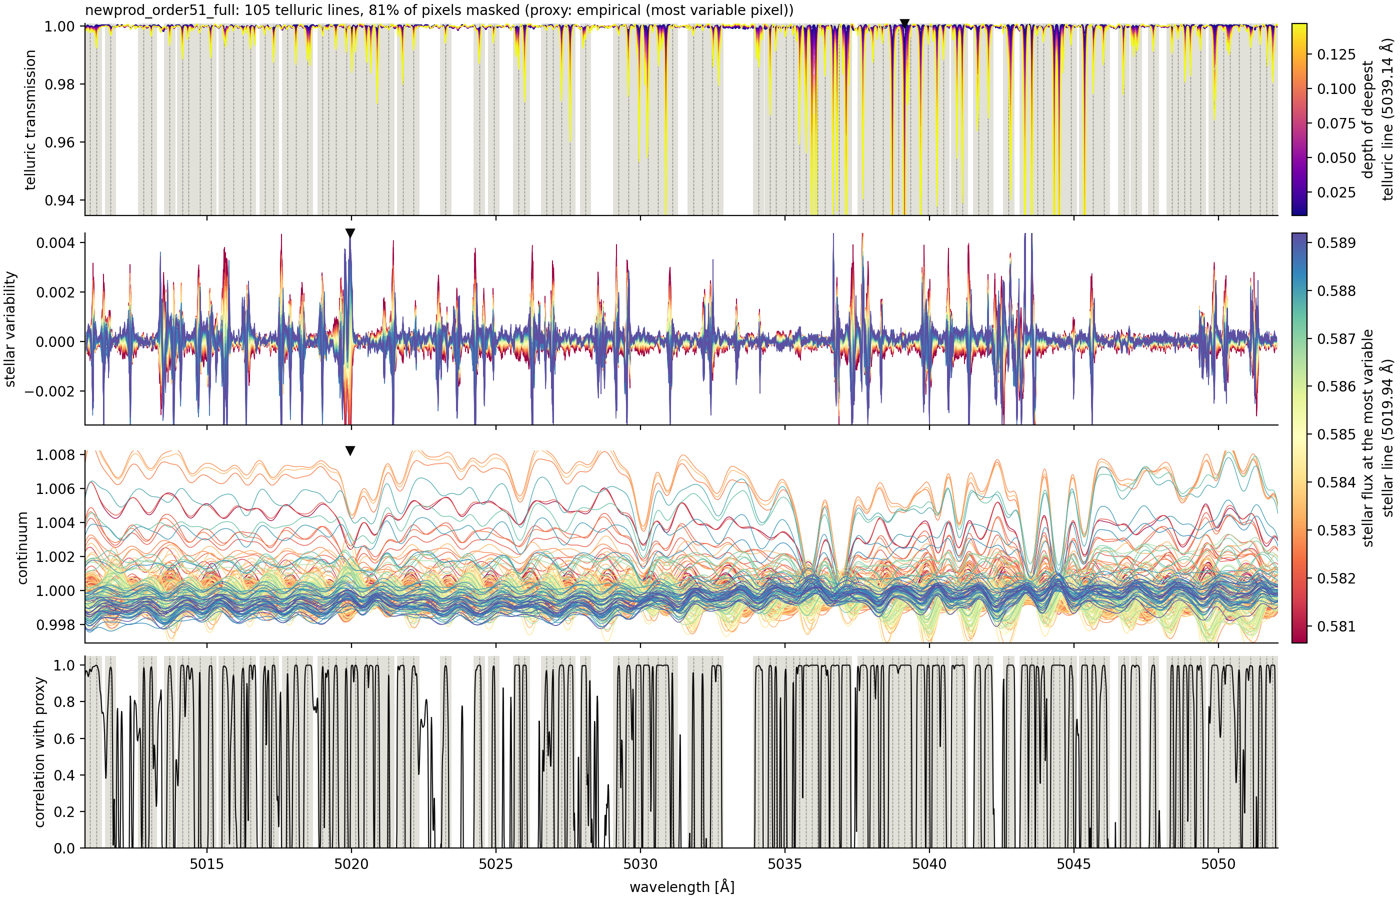

In [6]:
for o in ORDERS:
    !./calculate_skymask.py demo/skymodel/sky_order{o}_full.pt --dir demo/ --outdir demo/skymask --plot | tail -2
figure = PILImage.open("demo/skymask/newprod_order51_full-skymask.png")
figure.thumbnail((1400, 1400))   # smaller copy for the notebook
display(figure)

## 4. Cleaning and merging — `merge_orders.py`

`merge_orders.py` divides the telluric lines (inside the sky mask) and the
continuum out of every spectrum, rejects outlying pixels, and joins the orders
into one stellar spectrum per observation (Sec. 3.4):

In [7]:
# doubled braces: IPython would otherwise fill in {order} from Python variables
!./merge_orders.py --dir demo/ --orders 51 52 --models "demo/skymodel/sky_order{{order}}_{{when}}.pt" --masks "demo/skymask/{{data}}{{order}}_{{when}}-skymask.pt" | tail -3

saved demo/merged/newprod_merged_full_0.pt (500 spectra, 8040 pixels)
saved demo/merged/newprod_merged_full_1.pt (500 spectra, 8040 pixels)
saved demo/merged/newprod_merged_full-template.pt and demo/merged/newprod_merged_full-param.pt (1000 spectra, 8040 pixels)


The same observations before (resampled order spectra) and after (merged spectra),
around the deepest telluric line of each order and across the order boundary:

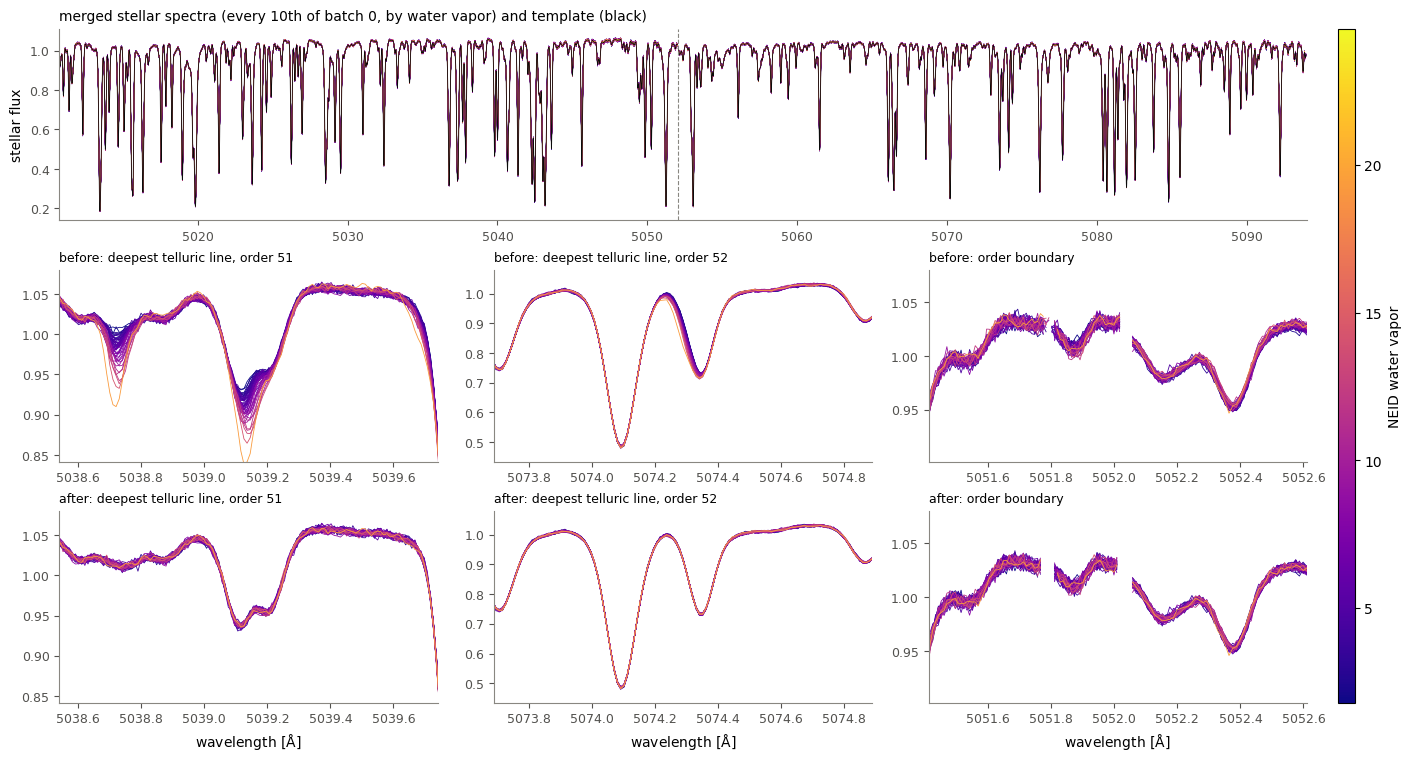

In [8]:
MERGED = f"{DEMO}/merged/newprod_merged_full"
wave_m, template_m, template_w = [t[0].numpy() for t in load_batch(f"{MERGED}-template.pt")[:3]]
meta = torch.load(f"{MERGED}-param.pt", weights_only=False)
merged_of = {np.float32(m["timestamp"]).item(): n for n, m in meta.items() if n != "info"}
merged = load_batch(f"{MERGED}_0.pt")
ids_m = np.array([s[4].item() for s in merged])
after = np.array([np.where(s[2].numpy() < 1e-3, np.nan, s[1].numpy()) for s in merged])

def raw_spectra(order, ids):
    # order spectra of batch file 0, resampled as merge_orders.py does before cleaning
    wave_o, template_o = [t.to(device) for t in load_batch(f"{DEMO}/newprod_order{order}_full-template.pt")[:2]]
    inst = SpectralData(wave_o)
    model_o = load_sky_model(f"{DEMO}/skymodel/sky_order{order}_full.pt", inst, device)
    b = [torch.stack(x).to(device) for x in zip(*load_batch(f"{DEMO}/newprod_order{order}_full_0.pt"))]
    with torch.no_grad():
        polyb = model_o.evaluate_wavelength_polynomial(b[0], b[4])
        spec, wt, _, raw_ids = interpolate_to_input_grid_raw(b, inst, template_o, polyb=polyb)
    row = {i: r for r, i in enumerate(raw_ids[:, 0].tolist())}
    rows = [row[i] for i in ids]
    return wave_o[0].cpu().numpy(), np.where(wt.cpu().numpy()[rows] > 1, spec.cpu().numpy()[rows], np.nan)

raw = {o: raw_spectra(o, ids_m) for o in ORDERS}
boundary = raw[52][0][0]
wv_m = np.array([meta[merged_of[i]]["WVAPOR"] for i in ids_m])
show = np.argsort(wv_m)[::10]
zooms = [(5039.14, "deepest telluric line, order 51"), (5074.29, "deepest telluric line, order 52"),
         (boundary, "order boundary")]

fig = plt.figure(figsize=(14, 7.5), constrained_layout=True)
gs = fig.add_gridspec(3, 3)
ax = fig.add_subplot(gs[0, :])
for r in show:
    ax.plot(wave_m, after[r], color=cmap(norm(wv_m[r])), lw=0.3)
ax.plot(wave_m, np.where(template_w > 0, template_m, np.nan), color="#0b0b0b", lw=0.6)
ax.axvline(boundary, color="#898781", ls="--", lw=0.8)
ax.set_xlim(wave_m[0], wave_m[-1])
ax.set_ylabel("stellar flux")
ax.set_title("merged stellar spectra (every 10th of batch 0, by water vapor) and template (black)", loc="left", fontsize=10)
style(ax)
for j, (center, label) in enumerate(zooms):
    window = (wave_m > center - 0.6) & (wave_m < center + 0.6)
    ylim = (max(np.nanmin(np.where(template_w > 0, template_m, np.nan)[window]) - 0.05, 0), 1.08)
    for i, stage in enumerate(("before", "after")):
        a = fig.add_subplot(gs[1 + i, j])
        for r in show:
            if stage == "before":
                for wo, spec in raw.values():
                    a.plot(wo, spec[r], color=cmap(norm(wv_m[r])), lw=0.6)
            else:
                a.plot(wave_m, after[r], color=cmap(norm(wv_m[r])), lw=0.6)
        a.set_xlim(center - 0.6, center + 0.6)
        a.set_ylim(*ylim)
        a.set_title(f"{stage}: {label}", loc="left", fontsize=9)
        style(a)
    a.set_xlabel(r"wavelength [$\mathrm{\AA}$]")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=fig.axes, label="NEID water vapor", pad=0.01, aspect=40);

## 5. Apparent RVs — `measure_apparent_rv.py`

The merged spectra still carry an apparent Doppler shift at the m/s level, from
stellar activity and any planets. `measure_apparent_rv.py` fits every spectrum with
the Doppler-shifted template (`TemplateFit`: cubic spline, weighted χ²) and adds
`v_app` to the merged param file (Sec. 3.5):

saved v_app for 1000 spectra to demo/merged/newprod_merged_full-param.pt: RMS 2.447 m/s, median chi^2 per pixel 0.48


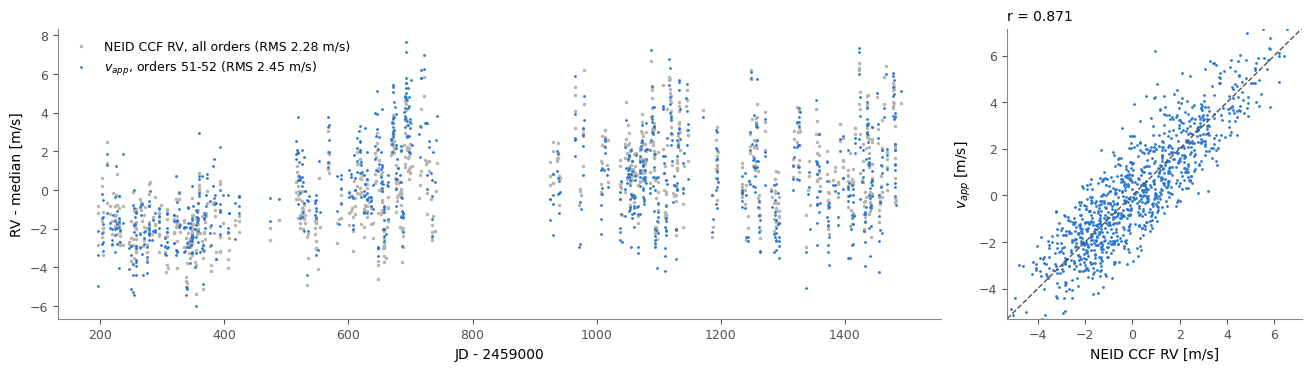

In [9]:
!./measure_apparent_rv.py --dir demo/ | tail -1

meta = torch.load(f"{MERGED}-param.pt", weights_only=False)
names = meta["info"]["sample_names"]
t = np.array([meta[n]["OBSJD"] for n in names]) - 2459000
v_app = np.array([meta[n]["v_app"] for n in names])
ccf = np.array([meta[n]["CCFRVMOD"] for n in names])
v_app, ccf = v_app - np.median(v_app), ccf - np.median(ccf)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), width_ratios=(3, 1), constrained_layout=True)
axs[0].plot(t, ccf, ".", ms=3, color="#b7b5ad", label=f"NEID CCF RV, all orders (RMS {ccf.std():.2f} m/s)")
axs[0].plot(t, v_app, ".", ms=2, color="#2a78d6", label=f"$v_{{app}}$, orders 51-52 (RMS {v_app.std():.2f} m/s)")
axs[0].set_xlabel("JD - 2459000"); axs[0].set_ylabel("RV - median [m/s]")
axs[0].legend(loc="upper left", fontsize=9, frameon=False)
axs[1].plot(ccf, v_app, ".", ms=2, color="#2a78d6")
lim = np.quantile(np.r_[ccf, v_app], [0.002, 0.998])
axs[1].plot(lim, lim, "--", color="#52514e", lw=1)
axs[1].set_xlim(lim); axs[1].set_ylim(lim)
axs[1].set_xlabel("NEID CCF RV [m/s]"); axs[1].set_ylabel("$v_{app}$ [m/s]")
axs[1].set_title(f"r = {np.corrcoef(v_app, ccf)[0, 1]:.3f}", loc="left", fontsize=10)
for ax in axs:
    style(ax)

## 6. Stellar activity representation — `stellar_training.py`, `export_latents.py`

The merged spectra, shifted to zero apparent RV, train an encoder-decoder whose
latents describe the activity state of every exposure (Sec. 4.1). The paper
setting is 20 latents and 10,000 epochs of one batch of 250 spectra:

```
./stellar_training.py --dir data/ -v stellar_model/stellar_s20.pt
```

The demo model was trained this way on the 1,000 demo spectra for 3,000 epochs.
Its loss history is stored in the checkpoint:

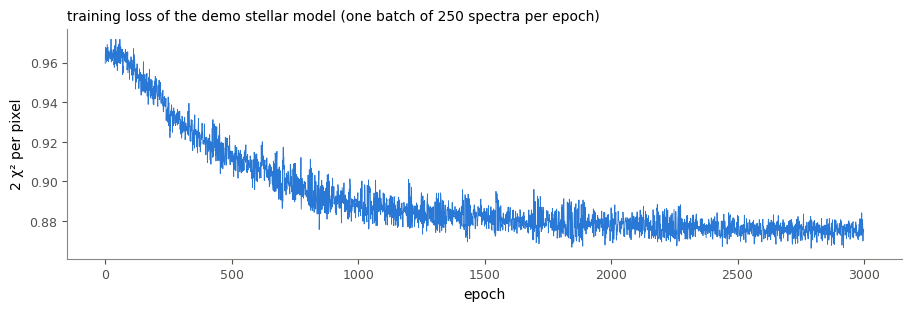

In [10]:
checkpoint = torch.load(f"{DEMO}/stellar_model/stellar_s20.pt", weights_only=False)
loss = checkpoint["losses"][0, 0, :, 0]
loss = loss[loss != 0]
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
ax.plot(loss, color="#2a78d6", lw=0.6)
ax.set_xlabel("epoch"); ax.set_ylabel("2 χ² per pixel")
ax.set_title("training loss of the demo stellar model (one batch of 250 spectra per epoch)", loc="left", fontsize=10)
style(ax)

`export_latents.py` encodes every spectrum with the trained model. The first
principal component of the latents follows the solar activity cycle:

saved demo/stellar_model/stellar_s20-latents.pt: 1000 spectra x 20 latents


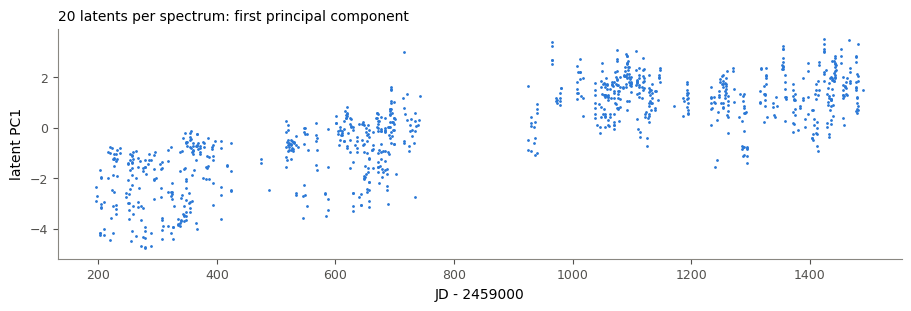

In [11]:
!./export_latents.py --dir demo/ demo/stellar_model/stellar_s20.pt | tail -1

latents = torch.load(f"{DEMO}/stellar_model/stellar_s20-latents.pt")
z = latents["latents"].numpy()
z = (z - z.mean(0)) / z.std(0)
pc1 = z @ np.linalg.svd(z, full_matrices=False)[2][0]
t_lat = latents["timestamp"].numpy()
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
ax.plot(t_lat, pc1, ".", ms=2, color="#2a78d6")
ax.set_xlabel("JD - 2459000"); ax.set_ylabel("latent PC1")
ax.set_title(f"{z.shape[1]} latents per spectrum: first principal component", loc="left", fontsize=10)
style(ax)

## 7. CCF activity indicators — `measure_ccf_indicators.py`

The traditional activity indicators (depth, FWHM, bisector span, offset of the
cross-correlation function, App. A.3) are used to detrend the RVs before the
candidate search in step 8:

In [12]:
!./measure_ccf_indicators.py --dir demo/ | tail -6

saved v_ccf, ccf_depth, ccf_fwhm, ccf_bis, ccf_offset for 1000 spectra to demo/merged/newprod_merged_full-param.pt
  v_ccf      median    -8.9298  RMS 2.7545
  ccf_depth  median     0.3749  RMS 0.0004
  ccf_fwhm   median     9.4432  RMS 0.0096
  ccf_bis    median   -28.0353  RMS 2.4529
  ccf_offset median     0.9552  RMS 0.0002


## 8. Injection and recovery — `search_candidates.py`, `rv_decomposition.py`

The last step splits the apparent RVs into stellar activity and planets (Sec. 4.2,
5.1–5.3). `rv_decomposition.py` injects a circular-orbit planet into the apparent
RVs, finds candidate periods with the traditional RV-level search of
`search_candidates.py` (CCF-indicator detrending, Lomb-Scargle periodograms,
sinusoid fits), and fits the activity RV estimator, a small network of the latents,
jointly with the candidate amplitudes in four period blocks.

This step is not run on the demo: with only 1,000 observations, the activity RV
estimator (3,731 parameters) can fit the apparent RVs almost exactly, and the
decomposition is not reliable. It needs a longer RV time series or more spectral
orders, like the ~29,000 spectra of 42 orders in the paper. On such data:

```
./rv_decomposition.py --dir data/ -v stellar_model/stellar_s20-latents.pt recovery.pt     # K = 0.5 m/s, P = 40 d
./rv_decomposition.py --dir data/ --amp 0.3 --period 12.5 --phase 0.25 stellar_model/stellar_s20-latents.pt recovery.pt
```

The pieces are also available from Python: `search_candidates.find_candidates` (the
candidate search), `rv_decomposition.RVDecomposition` (activity RV estimator plus
planets, from `models.ActivityEstimator` and `models.PlanetRV`) and
`rv_decomposition.train`.

## Next steps

* The README describes every script and its options.
* For the full analysis, download the NEID Level-2 files listed in `data/NEID_HIGH_QUALITY_OBSNAME.txt`
  from the [NEID Solar Archive](https://neid.ipac.caltech.edu/search_solar.php), prepare all
  42 orders with `prepare_orders.py` (this needs the NEID FSR mask), and train one telluric
  model per order (`skytrain.sh`) before continuing with steps 3–8.
* The paper's detection statistic and its calibration (Sec. 5.4) are not part of this code.